In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

In [2]:
df=pd.read_csv("/content/drive/MyDrive/data set.csv")
df.info()
print(df["FLAG"].value_counts())
print(df['FLAG'].value_counts(normalize=True))
#df.isna().sum().sum()
#df.head()
df.shape

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 42372 entries, 0 to 42371
Columns: 1036 entries, 1/1/2014 to FLAG
dtypes: float64(1034), int64(1), object(1)
memory usage: 334.9+ MB
FLAG
0    38757
1     3615
Name: count, dtype: int64
FLAG
0    0.914684
1    0.085316
Name: proportion, dtype: float64


(42372, 1036)

In [3]:
consumer_ids=df["CONS_NO"]
y=df["FLAG"]
ts_data=df.drop(columns=["CONS_NO","FLAG"])
ts_cleaned=(ts_data.T.interpolate(method='linear').ffill().bfill().fillna(0).T.astype("float32"))
print("Remaining missing values:", ts_cleaned.isna().sum().sum())
print("Shape of cleaned matrix:", ts_cleaned.shape)
ts_cleaned.head()

Remaining missing values: 0
Shape of cleaned matrix: (42372, 1034)


,1/1/2014,1/2/2014,1/3/2014,1/4/2014,1/5/2014,1/6/2014,1/7/2014,1/8/2014,1/9/2014,1/10/2014,...,10/22/2016,10/23/2016,10/24/2016,10/25/2016,10/26/2016,10/27/2016,10/28/2016,10/29/2016,10/30/2016,10/31/2016
0,0.0,0.0,0.01,0.0,0.0,0.00,0.00,0.00,0.00,0.00,...,0.020000,0.830000,0.020000,0.060000,0.580000,0.89,0.350000,0.380000,0.70,0.25
1,0.0,0.0,0.00,0.0,0.0,0.00,0.00,0.00,0.00,0.00,...,17.830000,23.910000,17.129999,14.320000,16.370001,26.33,19.059999,17.379999,13.94,14.14
2,0.0,0.0,0.00,0.0,0.0,4.98,9.87,11.29,13.44,11.34,...,1.953448,1.778965,1.604483,1.430000,2.220000,2.41,3.480000,2.890000,1.88,1.16
3,0.0,0.0,0.00,0.0,0.0,0.00,0.00,0.00,0.00,0.00,...,19.959999,19.500000,20.980000,18.469999,15.500000,14.80,19.280001,16.100000,17.51,16.67
4,0.0,0.0,0.00,0.0,0.0,0.00,0.00,0.00,0.00,0.00,...,2.140000,2.590000,0.610000,1.330000,0.550000,1.62,1.530000,2.100000,1.16,2.13


In [4]:
features = pd.DataFrame(index=ts_cleaned.index)
eps = 1e-6
features["mean"] = ts_cleaned.mean(axis=1)
features["std"] = ts_cleaned.std(axis=1)
features["var"] = ts_cleaned.var(axis=1)
features["median"] = ts_cleaned.median(axis=1)
features["min"] = ts_cleaned.min(axis=1)
features["max"] = ts_cleaned.max(axis=1)
features["cv"]=features["std"]/(features["mean"]+eps)
features["par"]=features["max"]/(features["mean"]+eps)
features["skew"] =ts_cleaned.skew(axis=1)
features["kurtosis"] = ts_cleaned.kurt(axis=1)
features["zero_days_count"]=(ts_cleaned==0.0).sum(axis=1)
features["zero_days_ratio"]= features["zero_days_count"] / ts_cleaned.shape[1]
recent_30_mean =ts_cleaned.iloc[:,-30:].mean(axis=1)
features["drop_ratio"]= recent_30_mean/(features["mean"]+eps)
print(features.isna().sum().sum())
print(features.isnull().sum().sum())
print(np.isinf(features).sum().sum())

features.shape

0
0
0


(42372, 13)

Calculated scale_pos_weight: 10.72
Model training completed successfully!

ROC-AUC Score: 0.7715
Optimal Balanced Threshold: 0.5000

=== CLASSIFICATION REPORT (Threshold = 0.50) ===
              precision    recall  f1-score   support

  Normal (0)       0.96      0.74      0.84      7752
   Fraud (1)       0.20      0.67      0.30       723

    accuracy                           0.74      8475
   macro avg       0.58      0.71      0.57      8475
weighted avg       0.90      0.74      0.79      8475



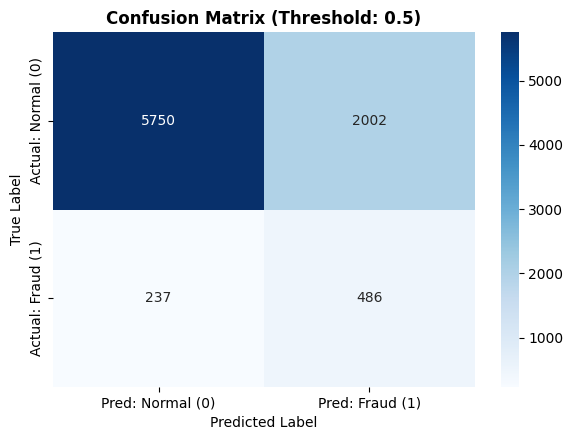

Optimized model saved successfully as: 'xgboost_optimized_detector.joblib'


In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_auc_score,
    precision_recall_curve
)
from xgboost import XGBClassifier

# 1. Stratified Train-Test Split
X = features
y = df["FLAG"].astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# 2. Calculate Exact Class Ratio for Native Weighting
neg_count = (y_train == 0).sum()
pos_count = (y_train == 1).sum()
scale_pos_weight = neg_count / pos_count
print(f"Calculated scale_pos_weight: {scale_pos_weight:.2f}")

# 3. Train Regularized XGBoost Directly on Real Data
xgb_model = XGBClassifier(
    n_estimators=180,
    max_depth=4,              # Moderate depth prevents memorizing noise
    learning_rate=0.05,        # Slower learning rate for smoother convergence
    scale_pos_weight=scale_pos_weight,  # Balances loss without SMOTE noise
    subsample=0.8,            # Prevents overfitting
    colsample_bytree=0.8,
    reg_alpha=1.0,            # L1 regularization
    reg_lambda=2.0,           # L2 regularization
    eval_metric='logloss',
    random_state=42
)

xgb_model.fit(X_train, y_train)
print("Model training completed successfully!")

# 4. Predict Probabilities & Compute ROC-AUC
y_pred_proba = xgb_model.predict_proba(X_test)[:, 1]
auc_score = roc_auc_score(y_test, y_pred_proba)
print(f"\nROC-AUC Score: {auc_score:.4f}")

# 5. Automatically find best threshold via Precision-Recall trade-off
precisions, recalls, thresholds = precision_recall_curve(y_test, y_pred_proba)
f1_scores = (2 * precisions * recalls) / (precisions + recalls + 1e-6)
best_idx = np.argmax(f1_scores)

optimal_threshold = 0.50
print(f"Optimal Balanced Threshold: {optimal_threshold:.4f}")
y_pred_custom = (y_pred_proba >= optimal_threshold).astype(int)

print(f"\n=== CLASSIFICATION REPORT (Threshold = {optimal_threshold:.2f}) ===")
print(classification_report(y_test, y_pred_custom, target_names=["Normal (0)", "Fraud (1)"]))

# 6. Plot Confusion Matrix
cm = confusion_matrix(y_test, y_pred_custom)
plt.figure(figsize=(6, 4.5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=["Pred: Normal (0)", "Pred: Fraud (1)"],
            yticklabels=["Actual: Normal (0)", "Actual: Fraud (1)"])
plt.title(f"Confusion Matrix (Threshold: {optimal_threshold})", fontsize=12, fontweight='bold')
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.tight_layout()
plt.show()

# 7. Save Final Model Artifact
model_path = "xgboost_optimized_detector.joblib"
joblib.dump(xgb_model, model_path)
print(f"Optimized model saved successfully as: '{model_path}'")

In [6]:
from sklearn.metrics import precision_score, recall_score
rows = []
for t in [0.3, 0.4, 0.5, 0.6, 0.7, 0.8]:
    pred = (y_pred_proba >= t).astype(int)
    rows.append({"Threshold": t,
                 "Precision": round(precision_score(y_test, pred), 3),
                 "Recall": round(recall_score(y_test, pred), 3),
                 "Flagged": int(pred.sum())})
pd.DataFrame(rows)

,Threshold,Precision,Recall,Flagged
0,0.3,0.122,0.896,5302
1,0.4,0.150,0.787,3806
2,0.5,0.195,0.672,2488
3,0.6,0.246,0.534,1569
4,0.7,0.305,0.382,906
5,0.8,0.410,0.196,346


In [ ]:
df.head(100).to_csv("sample_smart_meter_data.csv", index=False)

In [ ]:
# Generate a randomized 100-meter sample reflecting real-world distribution
df.sample(n=100, random_state=42).to_csv("realistic_sample_meters.csv", index=False)